In [108]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA

In [2]:

csv_path = Path("station_day.csv")
raw = pd.read_csv(csv_path, parse_dates=["Date"])

features = [
    "PM2.5", "PM10", "NO", "NO2", "NOx", "NH3",
    "CO", "SO2", "O3", "Benzene", "Toluene",
]

print("Размер исходной таблицы", raw.shape)
print("Доля пропусков по показателям, %")
print(raw[features + ["Xylene"]].isna().mean().mul(100).round(1))

Размер исходной таблицы (108035, 16)
Доля пропусков по показателям, %
PM2.5      20.0
PM10       39.5
NO         15.8
NO2        15.3
NOx        14.3
NH3        44.5
CO         12.0
SO2        23.3
O3         23.7
Benzene    29.1
Toluene    35.8
Xylene     78.8
dtype: float64


In [3]:
unique = raw.drop_duplicates()
clean = unique.dropna(subset=features).reset_index(drop=True)

X_raw = clean[features]
y_true = clean["AQI_Bucket"]

print("Удалено дубликатов", len(raw) - len(unique))
print("Удалено строк с пропусками в признаках", len(unique) - len(clean))
print("Осталось наблюдений и признаков", X_raw.shape)
print("Распределение категорий после очистки")
print(y_true.value_counts(dropna=False))

Удалено дубликатов 0
Удалено строк с пропусками в признаках 71471
Осталось наблюдений и признаков (36564, 11)
Распределение категорий после очистки
AQI_Bucket
Moderate        12939
Satisfactory     8396
Very Poor        4922
Poor             4893
Severe           2520
Good             2062
NaN               832
Name: count, dtype: int64


In [4]:
X_raw

,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene
0,71.36,115.75,1.75,20.65,12.40,12.19,0.10,10.76,109.26,0.17,5.92
1,81.40,124.50,1.44,20.50,12.08,10.72,0.12,15.24,127.09,0.20,6.50
2,78.32,129.06,1.26,26.00,14.85,10.28,0.14,26.96,117.44,0.22,7.95
3,88.76,135.32,6.60,30.85,21.77,12.91,0.11,33.59,111.81,0.29,7.63
4,64.18,104.09,2.56,28.07,17.01,11.42,0.09,19.00,138.18,0.17,5.02
...,...,...,...,...,...,...,...,...,...,...,...
36559,17.03,39.64,3.23,11.42,14.65,18.98,0.57,11.39,31.76,0.79,6.85
36560,9.79,19.87,23.51,16.50,40.02,25.09,0.66,10.34,30.19,0.93,6.37
36561,18.60,32.26,13.65,200.87,214.20,11.40,0.78,5.12,38.17,3.52,8.64
36562,16.07,39.30,7.56,29.13,36.69,29.26,0.69,5.88,29.64,1.86,8.40


In [5]:
y_true

0                 NaN
1            Moderate
2            Moderate
3            Moderate
4            Moderate
             ...     
36559    Satisfactory
36560            Good
36561    Satisfactory
36562    Satisfactory
36563    Satisfactory
Name: AQI_Bucket, Length: 36564, dtype: str

In [6]:
display(X_raw.corr().round(2))

means = X_raw.mean()
scales = X_raw.std(ddof=0).replace(0, 1)
X = (X_raw - means) / scales

print("Размер матрицы для кластеризации", X.shape)
print("Пропусков в матрице", X.isna().sum().sum())
display(X.head())

,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene
PM2.5,1.00,0.86,0.59,0.56,0.58,0.53,0.64,0.32,0.16,0.14,0.36
PM10,0.86,1.00,0.61,0.55,0.60,0.51,0.62,0.37,0.01,0.13,0.36
NO,0.59,0.61,1.00,0.65,0.87,0.42,0.65,0.29,0.04,0.19,0.35
NO2,0.56,0.55,0.65,1.00,0.76,0.40,0.56,0.37,0.26,0.12,0.28
NOx,0.58,0.60,0.87,0.76,1.00,0.44,0.62,0.33,0.13,0.18,0.29
NH3,0.53,0.51,0.42,0.40,0.44,1.00,0.44,0.26,0.13,0.05,0.22
CO,0.64,0.62,0.65,0.56,0.62,0.44,1.00,0.35,0.13,0.13,0.35
SO2,0.32,0.37,0.29,0.37,0.33,0.26,0.35,1.00,0.19,0.05,0.21
O3,0.16,0.01,0.04,0.26,0.13,0.13,0.13,0.19,1.00,-0.01,0.05
Benzene,0.14,0.13,0.19,0.12,0.18,0.05,0.13,0.05,-0.01,1.00,0.51


Размер матрицы для кластеризации (36564, 11)
Пропусков в матрице 0


,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene
0,-0.138418,-0.404412,-0.633033,-0.692831,-0.723052,-0.812522,-1.184415,-0.217304,1.251983,-0.306216,-0.460879
1,-0.010788,-0.337689,-0.641071,-0.697805,-0.729315,-0.882929,-1.161437,0.257432,1.593691,-0.303984,-0.442995
2,-0.049942,-0.302916,-0.645738,-0.515439,-0.675095,-0.904003,-1.138460,1.499377,1.408751,-0.302496,-0.398283
3,0.082772,-0.255181,-0.507279,-0.354625,-0.539642,-0.778037,-1.172926,2.201945,1.300853,-0.297288,-0.408150
4,-0.229690,-0.493326,-0.612030,-0.446802,-0.632815,-0.849402,-1.195904,0.655872,1.806229,-0.306216,-0.488632


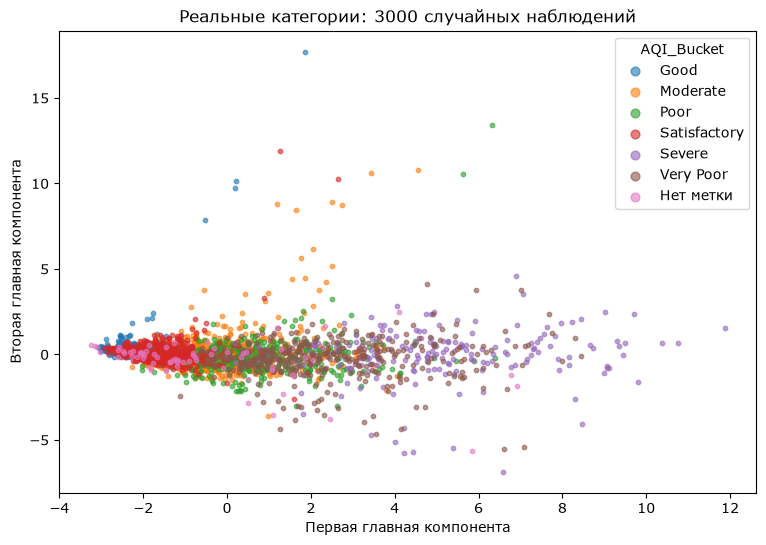

In [164]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

demo = clean.sample(n=3000, random_state=42).copy()

values = StandardScaler().fit_transform(demo[features])
demo[["PC1", "PC2"]] = PCA(n_components=2).fit_transform(values)
demo["Категория"] = demo["AQI_Bucket"].fillna("Нет метки")

plt.figure(figsize=(9, 6))

for category, group in demo.groupby("Категория"):
    plt.scatter(
        group["PC1"], group["PC2"],
        label=category, s=10, alpha=0.6,
    )

plt.xlabel("Первая главная компонента")
plt.ylabel("Вторая главная компонента")
plt.title("Реальные категории: 3000 случайных наблюдений")
plt.legend(title="AQI_Bucket", markerscale=2)
plt.show()

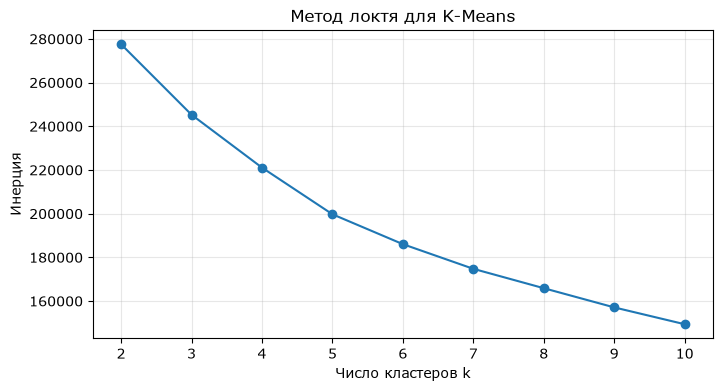

In [7]:
from sklearn.cluster import KMeans

k_values = range(2, 11)
inertias = []

for k in k_values:
    model = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=10,
        random_state=42,
    )
    model.fit(X)
    inertias.append(model.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(k_values, inertias, marker="o")
plt.xticks(k_values)
plt.xlabel("Число кластеров k")
plt.ylabel("Инерция")
plt.title("Метод локтя для K-Means")
plt.grid(alpha=0.3)
plt.show()

In [8]:
from sklearn.metrics import silhouette_score

scores = {}

for k in range(2, 11):
    labels = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=10,
        random_state=42,
    ).fit_predict(X)

    scores[k] = silhouette_score(
        X, labels, sample_size=3000, random_state=42
    )

silhouettes = pd.Series(scores, name="Средний силуэт")
silhouettes.index.name = "k"

display(silhouettes.round(4))
print("Лучшее k по силуэту =", silhouettes.idxmax())

k
2     0.4703
3     0.3060
4     0.3066
5     0.3092
6     0.2102
7     0.2115
8     0.2247
9     0.2158
10    0.2177
Name: Средний силуэт, dtype: float64

Лучшее k по силуэту = 2


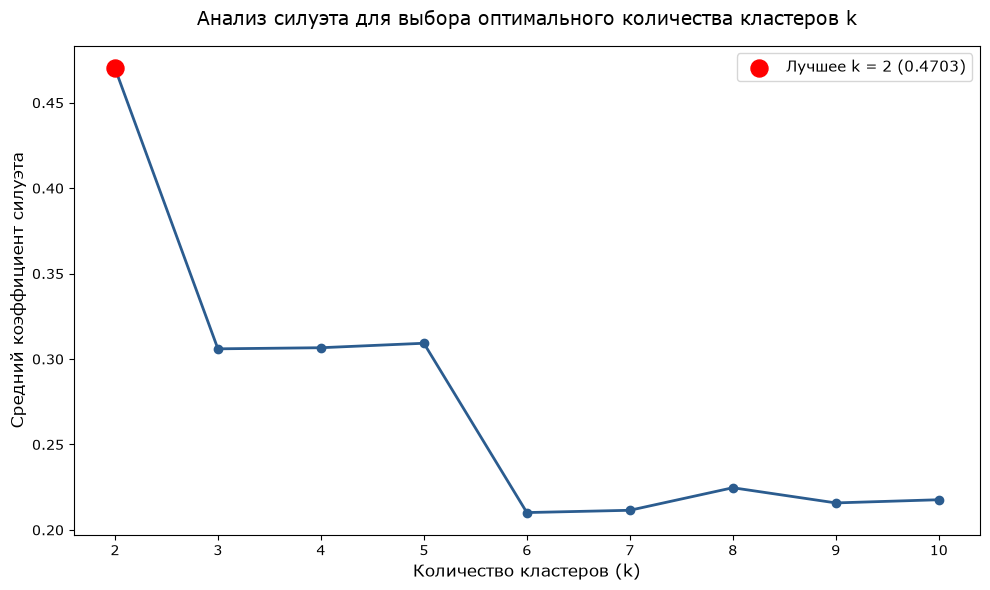

In [9]:
plt.figure(figsize=(10, 6))
plt.plot(silhouettes.index,silhouettes.values,marker="o",linestyle="-",linewidth=2,color="#2b5c8f")


best_k = silhouettes.idxmax()
best_score = silhouettes.max()
plt.scatter(
    best_k,
    best_score,
    color="red",
    s=150,
    zorder=5,
    label=f"Лучшее k = {best_k} ({best_score:.4f})",
)
plt.title("Анализ силуэта для выбора оптимального количества кластеров k",fontsize=14,pad=15,
)
plt.xlabel("Количество кластеров (k)", fontsize=12)
plt.ylabel("Средний коэффициент силуэта", fontsize=12)
plt.xticks(silhouettes.index)  
plt.legend(fontsize=11, loc="upper right")
plt.tight_layout()
plt.show()


In [ ]:
k = 2
k = best_k
initializations = ["k-means++", "random"]
seeds = range(42, 52)
runs = []
partitions = []


for init in initializations:
    for seed in seeds:
        model = KMeans(
            n_clusters=k,
            init=init,
            n_init=1,
            random_state=seed,
        ).fit(X)
        partitions.append(model.labels_.copy())

        runs.append({
            "init": init,
            "seed": seed,
            "inertia": model.inertia_,
            "iterations": model.n_iter_,
        })

results = pd.DataFrame(runs)

summary = results.groupby("init").agg(
    inertia_min=("inertia", "min"),
    inertia_mean=("inertia", "mean"),
    inertia_std=("inertia", "std"),
    iterations_mean=("iterations", "mean"),
)

display(summary.round(2))

,inertia_min,inertia_mean,inertia_std,iterations_mean
init,,,,
k-means++,277546.54,277547.01,0.33,9.7
random,277546.55,277547.09,0.27,10.7


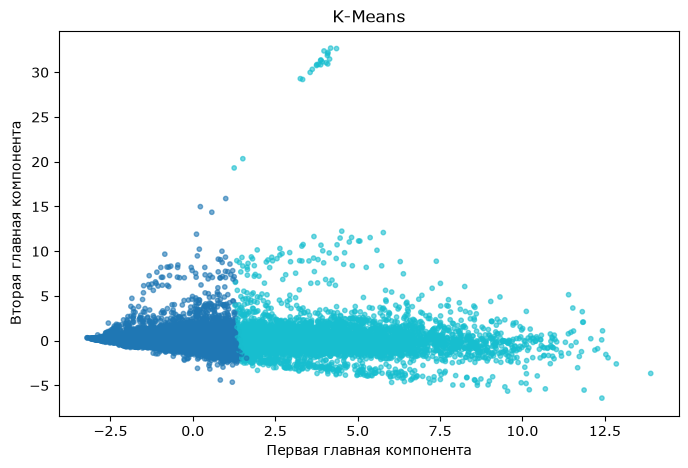

In [111]:
# Берём один запуск K-Means с минимальной инерцией.
labels_kmeans = partitions[int(results["inertia"].idxmin())]
X_kmeans_2d = PCA(n_components=2).fit_transform(X)

plt.figure(figsize=(8, 5))
plt.scatter(
    X_kmeans_2d[:, 0], X_kmeans_2d[:, 1],
    c=labels_kmeans, cmap="tab10", s=10, alpha=0.6,
)
plt.xlabel("Первая главная компонента")
plt.ylabel("Вторая главная компонента")
plt.title("K-Means")
plt.show()

In [11]:
results

,init,seed,inertia,iterations
0,k-means++,42,277547.319453,12
1,k-means++,43,277546.976993,12
2,k-means++,44,277547.401662,12
3,k-means++,45,277546.954431,11
4,k-means++,46,277546.769428,8
5,k-means++,47,277547.352967,6
6,k-means++,48,277546.535946,7
7,k-means++,49,277546.535946,10
8,k-means++,50,277547.319453,8
9,k-means++,51,277546.976993,11


In [12]:
from sklearn.cluster import AgglomerativeClustering

rng = np.random.default_rng(42)
sample_idx = rng.choice(len(X), size=min(3000, len(X)), replace=False)

X_sample = X.iloc[sample_idx]

# Строка — наблюдение, столбец — запуск K-Means.
ensemble_predictions = np.column_stack([
    labels[sample_idx] for labels in partitions
])

In [13]:
n_samples = len(X_sample)
co_association = np.zeros((n_samples, n_samples), dtype=np.float32)

for labels in ensemble_predictions.T:
    same_cluster = labels[:, None] == labels[None, :]
    co_association += same_cluster

co_association /= len(partitions)
distance_matrix = 1 - co_association

In [14]:
consensus = AgglomerativeClustering(
    n_clusters=k,
    metric="precomputed",
    linkage="average",
)

ensemble_labels = consensus.fit_predict(distance_matrix)

print("Размеры кластеров", np.bincount(ensemble_labels))

Размеры кластеров [2369  631]


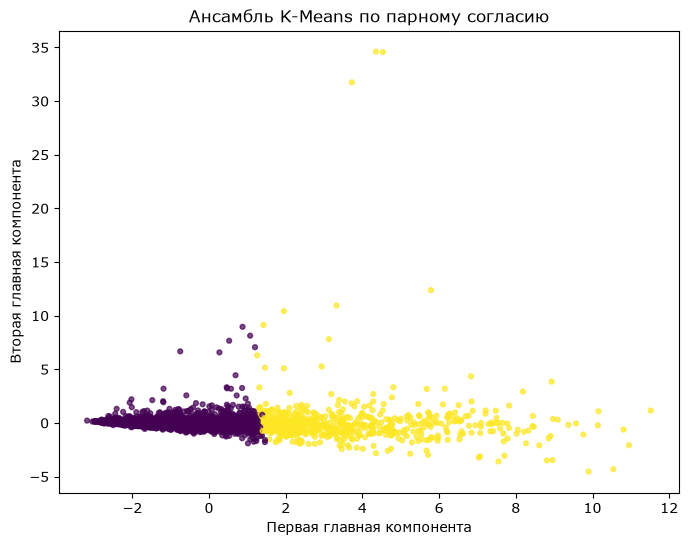

In [15]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

X_2d = PCA(n_components=2).fit_transform(X_sample)

plt.figure(figsize=(8, 6))
plt.scatter(
    X_2d[:, 0], X_2d[:, 1],
    c=ensemble_labels, cmap="viridis", s=12, alpha=0.7,
)
plt.xlabel("Первая главная компонента")
plt.ylabel("Вторая главная компонента")
plt.title("Ансамбль K-Means по парному согласию")
plt.show()

# DBSCAN

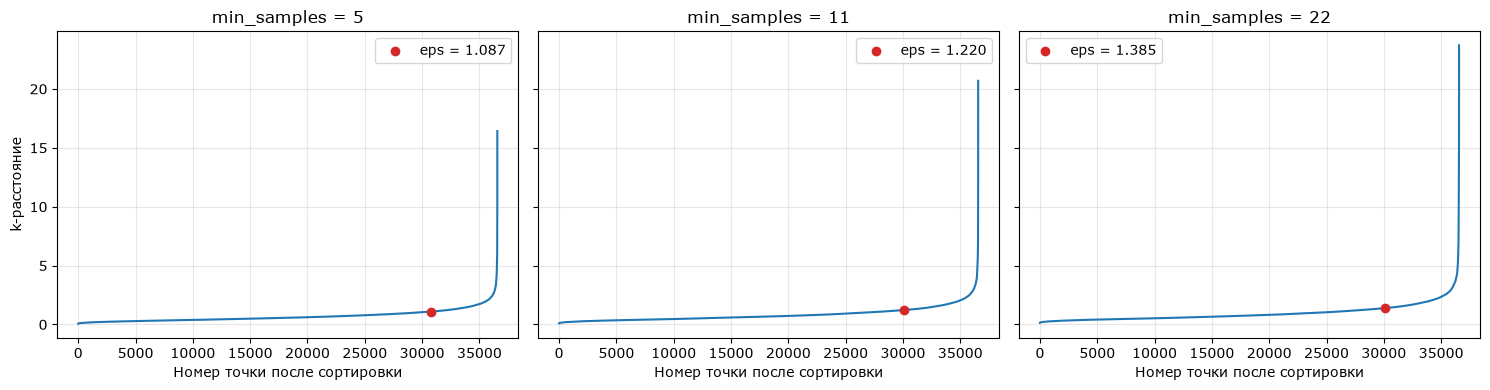

,min_samples,eps,Кластеров,"Покрытие, %",Силуэт
0,5,1.087,43,88.368,0.119
1,11,1.220,11,88.437,0.385
2,22,1.385,2,89.320,0.580


In [26]:
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import adjusted_rand_score, silhouette_score

db_candidates = []
dbscan_labels = {}

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)

for min_samples, ax in zip([5, 11, 22], axes):
    neighbors = NearestNeighbors(
        n_neighbors=min_samples,
        metric="euclidean",
    ).fit(X)

    distances, _ = neighbors.kneighbors(X)
    k_distances = np.sort(distances[:, -1])

    # 2. Исключаем верхний 1% расстояний только из поиска локтя.
    body = k_distances[:int(0.99 * len(k_distances))]

    # 3. Автоматически находим локоть.
    if body[-1] > body[0]:
        positions = np.linspace(0, 1, len(body))
        scaled_distances = (body - body[0]) / (body[-1] - body[0])
        knee = int(np.argmax(positions - scaled_distances))
    else:
        knee = 0

    eps = max(float(body[knee]), np.finfo(float).eps)

    # 4. Выполняем DBSCAN с выбранным eps.
    labels = DBSCAN(
        eps=eps,
        min_samples=min_samples,
        metric="euclidean",
    ).fit_predict(X)

    dbscan_labels[min_samples] = labels

    # 5. Рассчитываем показатели без учёта шума.
    assigned = labels != -1
    n_assigned = int(assigned.sum())
    n_clusters = np.unique(labels[assigned]).size
    coverage = assigned.mean()

    score = np.nan
    if 2 <= n_clusters < n_assigned:
        score = silhouette_score(
            X[assigned],
            labels[assigned],
            metric="euclidean",
        )

    db_candidates.append({
        "min_samples": min_samples,
        "eps": eps,
        "Кластеров": n_clusters,
        "Покрытие, %": coverage * 100,
        "Силуэт": score,
    })

    # 6. Отмечаем выбранный eps на соответствующем графике.
    ax.plot(k_distances)
    ax.scatter(
        knee,
        eps,
        color="tab:red",
        zorder=3,
        label=f"eps = {eps:.3f}",
    )
    ax.set_title(f"min_samples = {min_samples}")
    ax.set_xlabel("Номер точки после сортировки")
    ax.legend()
    ax.grid(alpha=0.3)
axes[0].set_ylabel("k-расстояние")
fig.tight_layout()
plt.show()

# Общая таблица для трёх вариантов.
db_table = pd.DataFrame(db_candidates)
display(db_table.round(3))

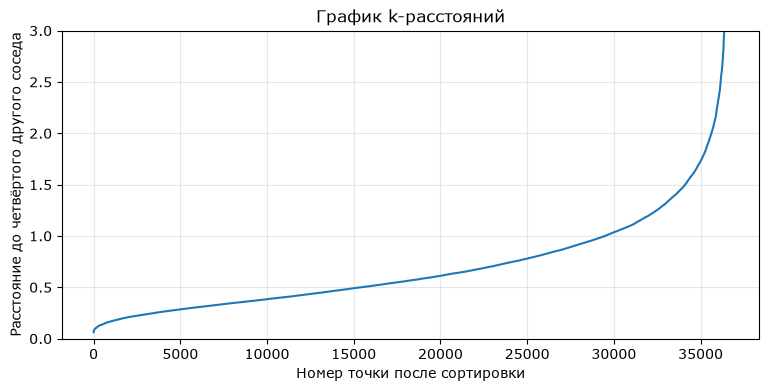

In [23]:
neighbors = NearestNeighbors(
    n_neighbors=min_samples,
    metric="euclidean",
).fit(X)

distances, _ = neighbors.kneighbors(X)
k_distances = np.sort(distances[:, -1])

plt.figure(figsize=(9, 4))
plt.plot(k_distances)
plt.ylim(0, 3)
plt.xlabel("Номер точки после сортировки")
plt.ylabel("Расстояние до четвёртого другого соседа")
plt.title("График k-расстояний")
plt.grid(alpha=0.3)
plt.show()

In [24]:
rows = []
labels_by_eps = {}

for eps in [1.50, 1.509, 1.7]:
    labels = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X)
    labels_by_eps[eps] = labels

    noise = labels == -1
    sizes = pd.Series(labels[~noise]).value_counts()

    rows.append({
        "eps": eps,
        "Число кластеров": len(sizes),
        "Шум, %": round(100 * noise.mean(), 2),
        "Размер крупнейшего кластера": sizes.max(),
    })

display(pd.DataFrame(rows))

,eps,Число кластеров,"Шум, %",Размер крупнейшего кластера
0,1.500,22,4.41,34796
1,1.509,24,4.32,34821
2,1.700,18,2.79,35434


In [27]:
db_eps = 1.385
db_min_samples = 22
SEED = 42

# Исследование чувствительности алгоритма к шумам и выбросам

In [30]:
rng = np.random.default_rng(SEED)
n_added = len(X) // 20  # Добавляем 5% от размера исходной выборки.
low, high = np.quantile(X, [0.10, 0.90], axis=0)
background = rng.uniform(low, high, size=(n_added, X.shape[1]))
max_values = np.asarray(X.max(axis=0))
far_outliers = (max_values + db_eps + rng.uniform(1, 10, size=background.shape)
)

sensitivity = []
for name, added in [("База", X[:0]), ("Фоновый шум", background), ("Далёкие выбросы", far_outliers)]:
    labels = DBSCAN(eps=db_eps, min_samples=db_min_samples).fit_predict(np.vstack([X, added]))
    original_labels = labels[:len(X)]
    sensitivity.append({
        "Сценарий": name,
        "Кластеров среди исходных": len(set(original_labels) - {-1}),
        "Шум среди исходных, %": 100 * np.mean(original_labels == -1),
        "Шум среди добавленных, %": 100 * np.mean(labels[len(X):] == -1) if len(added) else np.nan,
        "ARI с базой на исходных": adjusted_rand_score(dbscan_labels[db_min_samples], original_labels),
    })

display(pd.DataFrame(sensitivity).round(3))

,Сценарий,Кластеров среди исходных,"Шум среди исходных, %","Шум среди добавленных, %",ARI с базой на исходных
0,База,2,10.680,NaN,1.000
1,Фоновый шум,2,10.642,0.602,0.998
2,Далёкие выбросы,2,10.680,100.000,1.000


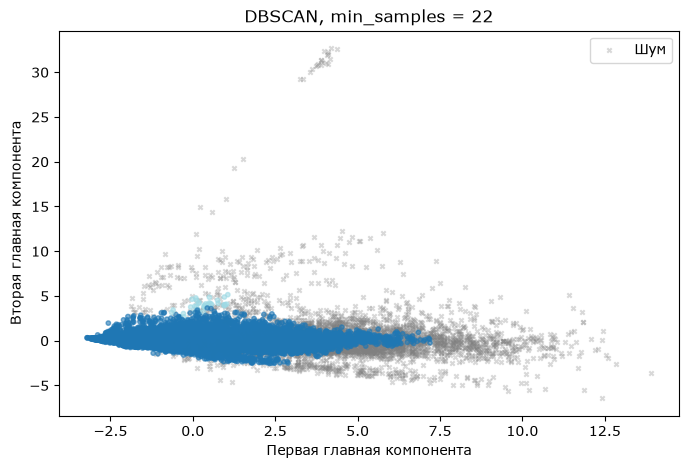

In [ ]:
labels_db = dbscan_labels[db_min_samples]
X_db_2d = PCA(n_components=2).fit_transform(X)
noise = labels_db == -1

plt.figure(figsize=(8, 5))
plt.scatter(
    X_db_2d[noise, 0], X_db_2d[noise, 1],
    color="gray", marker="x", s=10, alpha=0.3, label="Шум",
)
plt.scatter(
    X_db_2d[~noise, 0], X_db_2d[~noise, 1],
    c=labels_db[~noise], cmap="tab20", s=10, alpha=0.6,
)
plt.xlabel("Первая главная компонента")
plt.ylabel("Вторая главная компонента")
plt.title(f"DBSCAN, min_samples = {db_min_samples}")
plt.legend()
plt.show()

# Иерархическая кластеризация

### Эксперимент с удалением по межквартальному размаху

In [83]:
from sklearn.preprocessing import StandardScaler

q1 = X_raw.quantile(0.25)
q3 = X_raw.quantile(0.75)
iqr = q3 - q1

lower = q1 - 3 * iqr
upper = q3 + 3 * iqr

# True означает, что конкретное значение вышло за границы.
outlier_cells = X_raw.lt(lower) | X_raw.gt(upper)

# Удаляем строку, если хотя бы один признак вышел за границы.
keep_rows = ~outlier_cells.any(axis=1)

X_raw_filtered = X_raw.loc[keep_rows].copy()

print(f"До фильтрации: {len(X_raw)}")
print(f"После фильтрации: {len(X_raw_filtered)}")
print(f"Удалено: {(~keep_rows).sum()} ({(~keep_rows).mean():.1%})")

# Одну строку могут отметить сразу несколько признаков.
display(
    outlier_cells.sum()
    .sort_values(ascending=False)
    .rename("Число выходов за границы")
)

scaler = StandardScaler()
X_raw_filtered = scaler.fit_transform(X_raw_filtered)

До фильтрации: 36564
После фильтрации: 31164
Удалено: 5400 (14.8%)


NO         2056
NOx        1183
Toluene    1172
O3         1014
PM2.5      1005
Benzene     991
CO          502
SO2         262
NH3         212
NO2         179
PM10        161
Name: Число выходов за границы, dtype: int64

In [84]:
from scipy.cluster.hierarchy import cut_tree, dendrogram, linkage, fcluster
from time import perf_counter

In [117]:
X_ierarchical = X_raw_filtered.copy()
# X_ierarchical = X.copy()

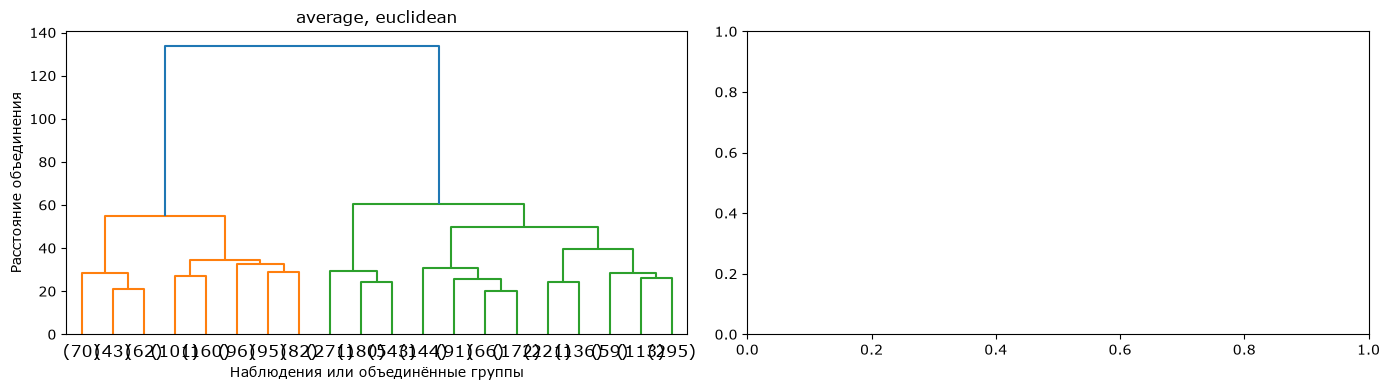

In [124]:
# Одинаковая подвыборка для обеих метрик.
distances_to_compare = {"Евклидова": "euclidean", "Манхэттенская": "cityblock"}
rng = np.random.default_rng(42)
sample_idx = rng.choice(
    len(X_ierarchical),
    size=min(3000, len(X)),
    replace=False,
)

# Переводим DataFrame в NumPy и выбираем строки.
X_hier = np.asarray(X_ierarchical, dtype=float)[sample_idx]

trees = {}
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

for metric, ax in zip(["euclidean"], axes):
    # Строим дерево всех последовательных объединений.
    tree = linkage(X_hier, method="ward", metric=metric)
    trees[metric] = tree

    # Показываем верхнюю часть дерева в сокращённом виде.
    dendrogram(
        tree,
        truncate_mode="lastp",
        p=20,
        ax=ax,
    )

    ax.set_title(f"average, {metric}")
    ax.set_xlabel("Наблюдения или объединённые группы")
    ax.set_ylabel("Расстояние объединения")

fig.tight_layout()
plt.show()

In [126]:
cut_heights = {
    "euclidean": 100,
    # "cityblock": 23,
}
hierarchy_labels = {}
comparison = []

for metric, height in cut_heights.items():
    labels = fcluster(
        trees[metric],
        t=height,
        criterion="distance",
    )
    hierarchy_labels[metric] = labels

    sizes = pd.Series(labels).value_counts()

    comparison.append({
        "Метрика": metric,
        "Высота разреза": height,
        "Число кластеров": len(sizes),
        "Размеры кластеров": sizes.tolist(),
    })

display(pd.DataFrame(comparison))

# Сравниваем принадлежность одних и тех же точек к кластерам.
# ari = adjusted_rand_score(
#     hierarchy_labels["euclidean"],
#     hierarchy_labels["cityblock"],
# )
print(f"ARI между разбиениями: {ari:.3f}")

,Метрика,Высота разреза,Число кластеров,Размеры кластеров
0,euclidean,100,2,"[2291, 709]"


ARI между разбиениями: 1.000


Метрика,Евклидова,Манхэттенская
Строк,,
500,0.0041,0.0025
1000,0.0114,0.0110
2000,0.0487,0.0444
3000,0.1002,0.0946
5000,0.2823,0.3142
10000,1.9557,1.8990


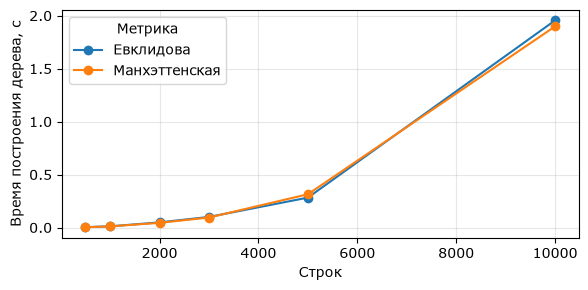

In [64]:
timings = []
for size in [500, 1000, 2000, 3000, 5000, 10000]:
    if size > len(X):
        continue

    for name, metric in distances_to_compare.items():
        elapsed = []
        for _ in range(3):
            start = perf_counter()
            linkage(X[:size], method="average", metric=metric)
            elapsed.append(perf_counter() - start)

        timings.append({"Строк": size, "Метрика": name, "Секунды": np.median(elapsed)})

time_table = pd.DataFrame(timings).pivot(index="Строк", columns="Метрика", values="Секунды")
display(time_table.round(4))
ax = time_table.plot(marker="o", figsize=(6, 3))
ax.set_ylabel("Время построения дерева, с")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

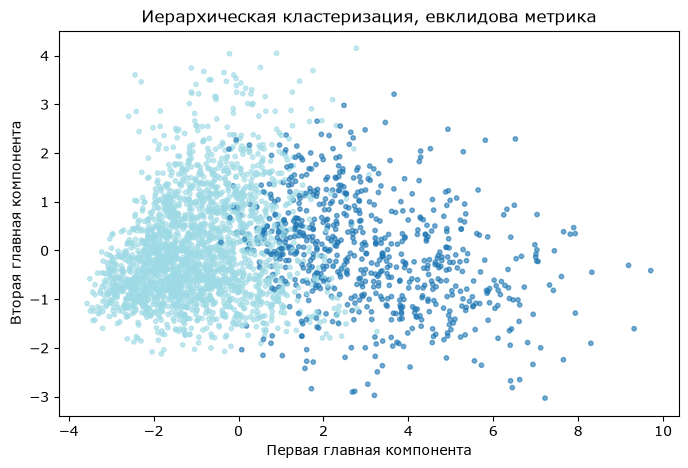

In [127]:
# Используем метки, рассчитанные для этой же подвыборки X_hier.
labels_hier_plot = hierarchy_labels["euclidean"]
X_hier_2d = PCA(n_components=2).fit_transform(X_hier)

plt.figure(figsize=(8, 5))
plt.scatter(
    X_hier_2d[:, 0], X_hier_2d[:, 1],
    c=labels_hier_plot, cmap="tab20", s=10, alpha=0.6,
)
plt.xlabel("Первая главная компонента")
plt.ylabel("Вторая главная компонента")
plt.title("Иерархическая кластеризация, евклидова метрика")
plt.show()